<a href="https://colab.research.google.com/github/annjerinsundar-code/ICTAK-AI-ML-Coursework/blob/main/CaseStudy_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [60]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('/content/train_loan.csv')

# Displays first five records of the dataset
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


#INSPECTING DATASET

In [61]:
# Dimension of the dataframe
print("Dataset shape:", df.shape)

# Returns the overall information regarding data types and non - null counts in the dataset
print("\n\nData types and non-null counts:\n")
df.info()

# Returns the descriptive statistics
print("\n\n\nNumerical summary:")
print(df.describe())


Dataset shape: (614, 13)


Data types and non-null counts:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB



Numerical summary:
       ApplicantIncome  Coappl

#PREPROCESSING STEPS

###MISSING VALUE HANDLING

In [62]:
# Check for duplicate values
df.duplicated().sum()

np.int64(0)

In [63]:
# Missing value count and percentage in respective columns; in descending order

missing_values = df.isnull().sum()
print(pd.DataFrame({"Missing Count": missing_values, "Missing Percentage (%)": (missing_values / len(df) * 100).round(2)}).query("`Missing Count` > 0").sort_values("Missing Count", ascending=False))

                  Missing Count  Missing Percentage (%)
Credit_History               50                    8.14
Self_Employed                32                    5.21
LoanAmount                   22                    3.58
Dependents                   15                    2.44
Loan_Amount_Term             14                    2.28
Gender                       13                    2.12
Married                       3                    0.49


In [64]:
# Create a copy of the original dataset
df_clean = df.copy()

# Separate numerical and categorical columns for imputation
numeric_cols = df_clean.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df_clean.select_dtypes(include=["object", "category"]).columns.tolist()

# Loan_ID is an identifier, not a useful measurement to impute
if "Loan_ID" in categorical_cols:
    categorical_cols.remove("Loan_ID")

# Impute numerical columns using the median
for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Impute categorical columns using the mode
for col in categorical_cols:
    if df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

print("Missing values after imputation:")
print(df_clean.isnull().sum().to_frame("Missing Count"))

Missing values after imputation:
                   Missing Count
Loan_ID                        0
Gender                         0
Married                        0
Dependents                     0
Education                      0
Self_Employed                  0
ApplicantIncome                0
CoapplicantIncome              0
LoanAmount                     0
Loan_Amount_Term               0
Credit_History                 0
Property_Area                  0
Loan_Status                    0


In [65]:
# Cleaned data info
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             614 non-null    object 
 2   Married            614 non-null    object 
 3   Dependents         614 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      614 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         614 non-null    float64
 9   Loan_Amount_Term   614 non-null    float64
 10  Credit_History     614 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


### OUTLIER DETECTION

In [66]:
# Numerical summary of cleaned data to analyze skewness
df_clean.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,614.000000,614.000000,614.000000
mean,5403.459283,1621.245798,145.752443,342.410423,0.855049
std,6109.041673,2926.248369,84.107233,64.428629,0.352339
min,150.000000,0.000000,9.000000,12.000000,0.000000
25%,2877.500000,0.000000,100.250000,360.000000,1.000000
50%,3812.500000,1188.500000,128.000000,360.000000,1.000000
75%,5795.000000,2297.250000,164.750000,360.000000,1.000000
max,81000.000000,41667.000000,700.000000,480.000000,1.000000


In [67]:
# Skewness check
df_clean.select_dtypes("number").skew().sort_values(ascending=False) #desc

,0
CoapplicantIncome,7.491531
ApplicantIncome,6.539513
LoanAmount,2.743053
Credit_History,-2.021971
Loan_Amount_Term,-2.402112


ApplicantIncome
6.539513113994625


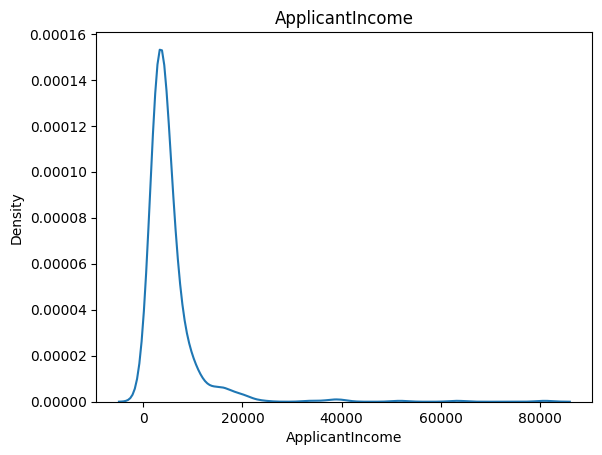

CoapplicantIncome
7.491531216657306


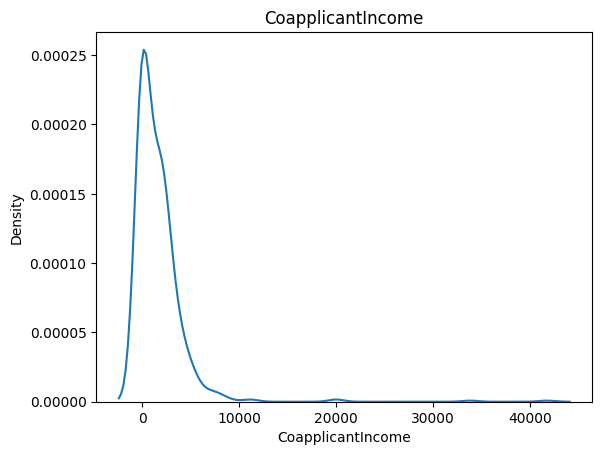

LoanAmount
2.743052748820892


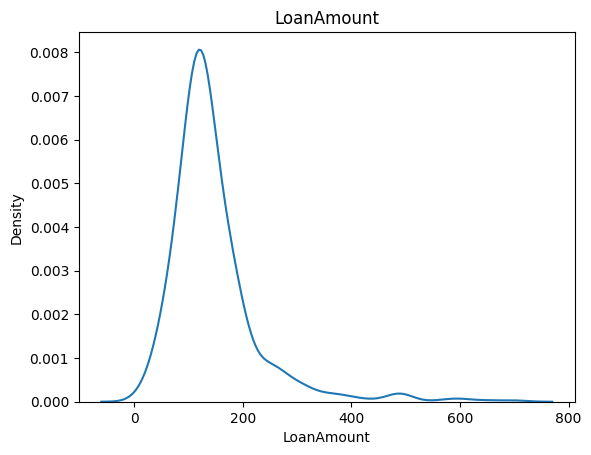

Loan_Amount_Term
-2.4021122563890396


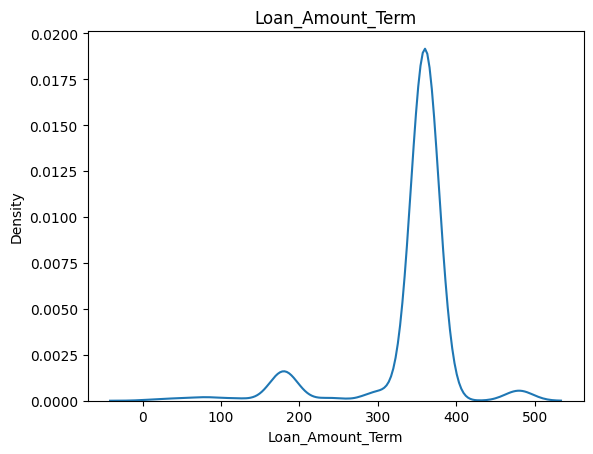

Credit_History
-2.0219705924848985


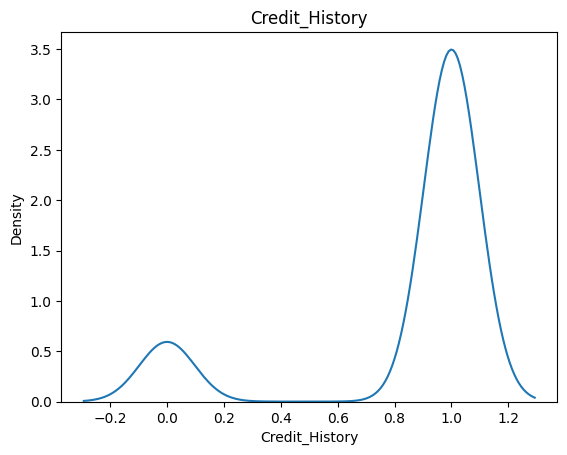

In [68]:
# Plot kdeplots to visually identify potential outliers
for i in df_clean.select_dtypes("number").columns:
  print(i)
  sns.kdeplot(df_clean[i])
  plt.title(i)
  print(df_clean[i].skew())
  plt.show(i)


ApplicantIncome


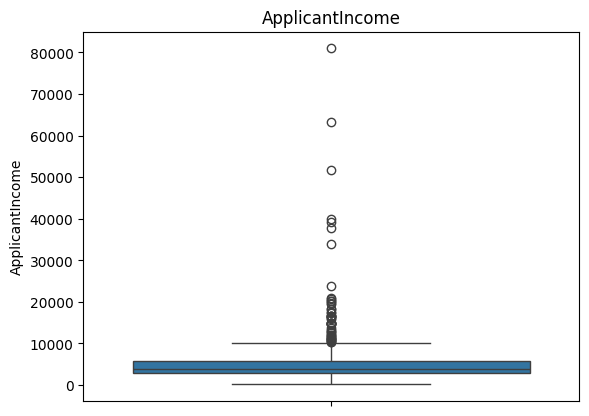

CoapplicantIncome


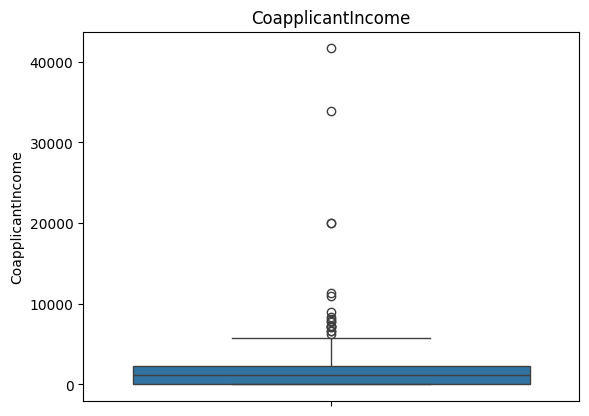

LoanAmount


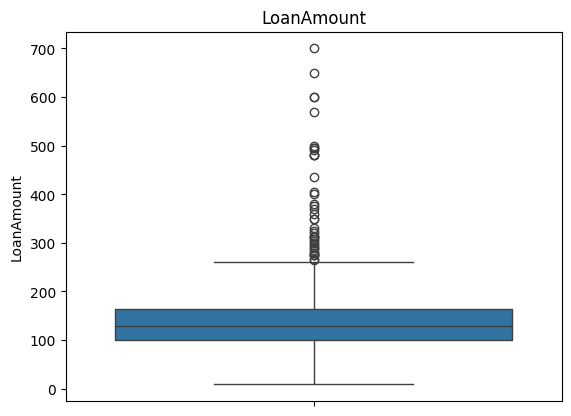

Loan_Amount_Term


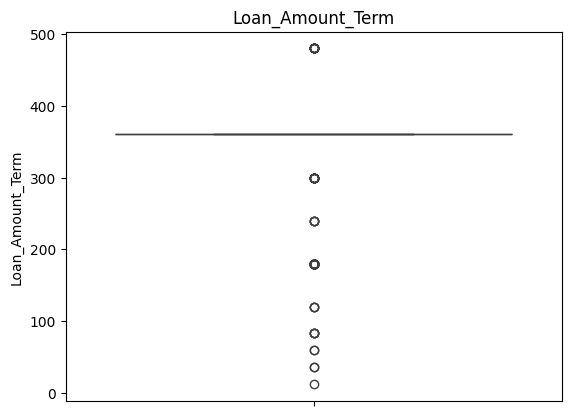

Credit_History


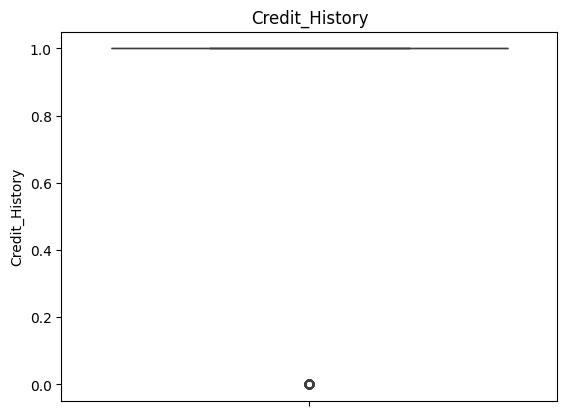

In [69]:
# Plot boxplots to visually identify potential outliers
for i in df_clean.select_dtypes("number").columns:
  print(i)
  sns.boxplot(df_clean[i])
  plt.title(i)
  plt.show()

6.539513113994625


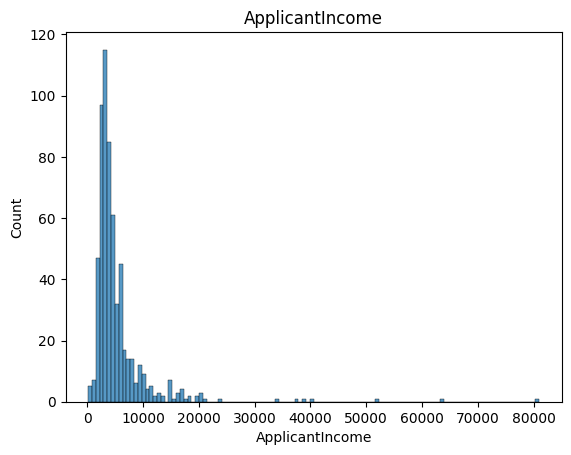

7.491531216657306


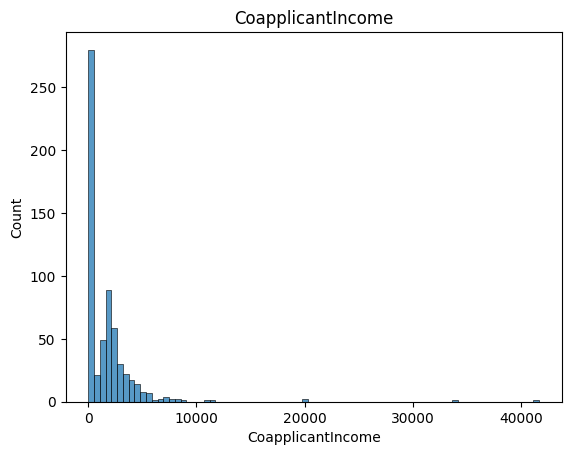

2.743052748820892


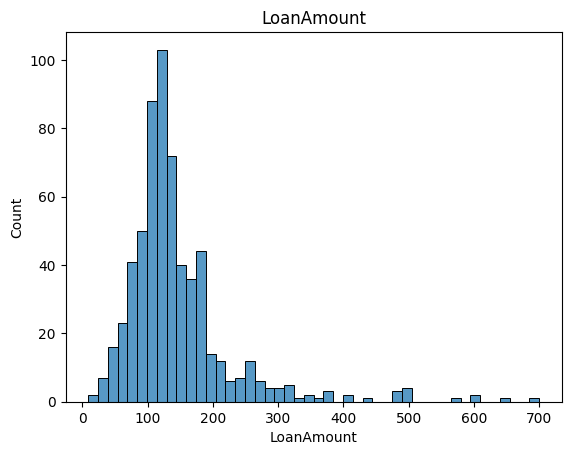

-2.4021122563890396


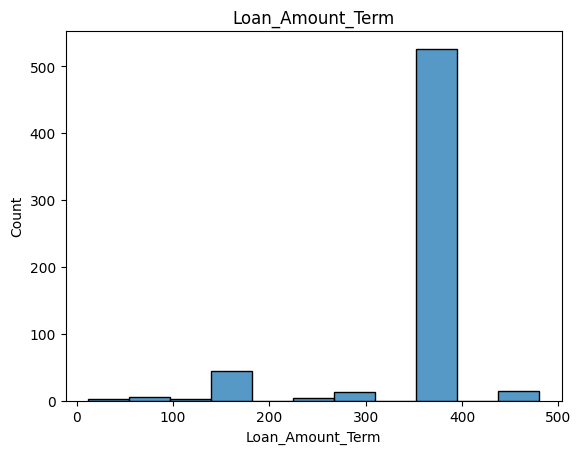

-2.0219705924848985


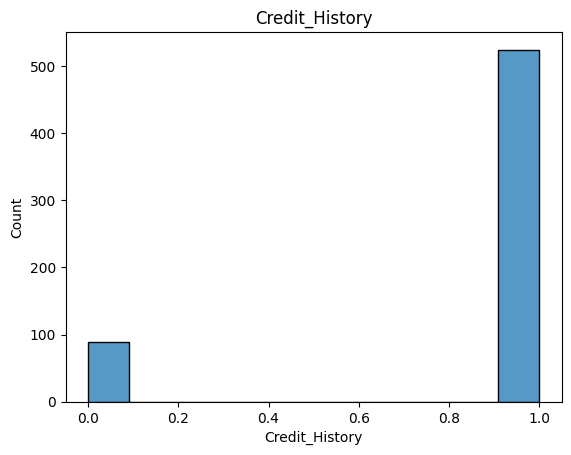

In [70]:
# Plot histplots to visually identify potential outliers

for i in df_clean.select_dtypes("number").columns:
  sns.histplot(df_clean[i])
  plt.title(i)
  print(df_clean[i].skew())
  plt.show(i)

In [71]:
# Function to remove outliers using IQR
def remove_outliers(df, columns):
    df_filtered = df  # Make a copy of the original DataFrame
    for i in columns:
        Q1 = df[i].quantile(0.25)
        Q3 = df[i].quantile(0.75)
        IQR = Q3 - Q1
        lower_whisker = Q1 - 1.5 * IQR
        upper_whisker = Q3 + 1.5 * IQR
        # Filter out rows where column values are outliers
        df_filtered = df_filtered[(df_filtered[i] >= lower_whisker) & (df_filtered[i] <= upper_whisker)]
    return df_filtered

In [72]:
# Find the numerical columns for detecting and removing outliers
numerical_cols = df_clean.select_dtypes(include='number').columns.tolist()
numerical_cols

['ApplicantIncome',
 'CoapplicantIncome',
 'LoanAmount',
 'Loan_Amount_Term',
 'Credit_History']

In [73]:
df_without_outlier = remove_outliers(df_clean,numerical_cols)
df_without_outlier

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,128.0,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
...,...,...,...,...,...,...,...,...,...,...,...,...,...
607,LP002964,Male,Yes,2,Not Graduate,No,3987,1411.0,157.0,360.0,1.0,Rural,Y
608,LP002974,Male,Yes,0,Graduate,No,3232,1950.0,108.0,360.0,1.0,Rural,Y
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y


ApplicantIncome


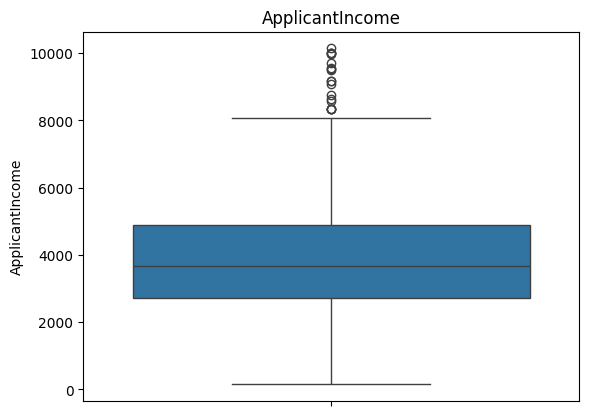

CoapplicantIncome


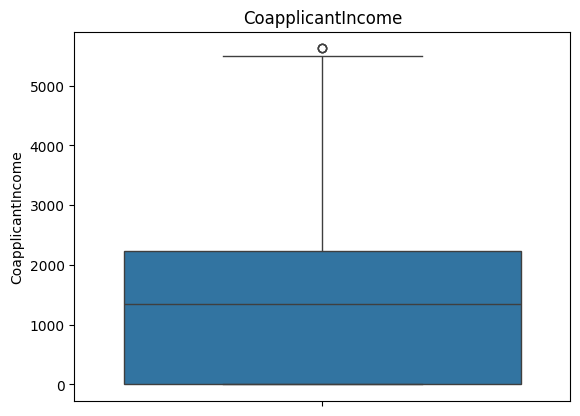

LoanAmount


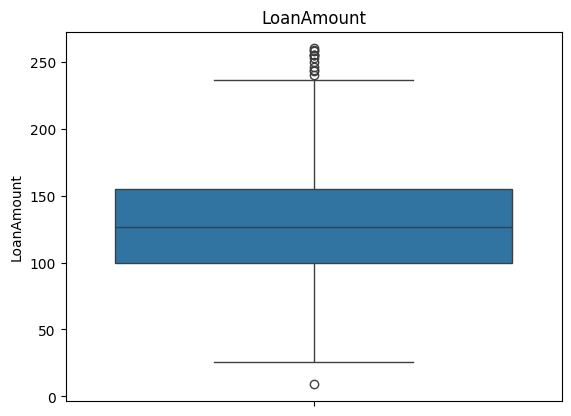

Loan_Amount_Term


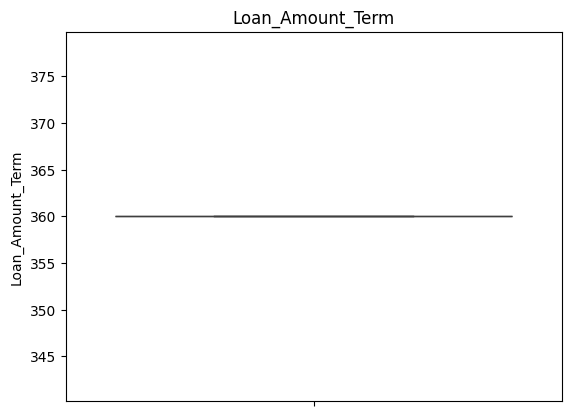

Credit_History


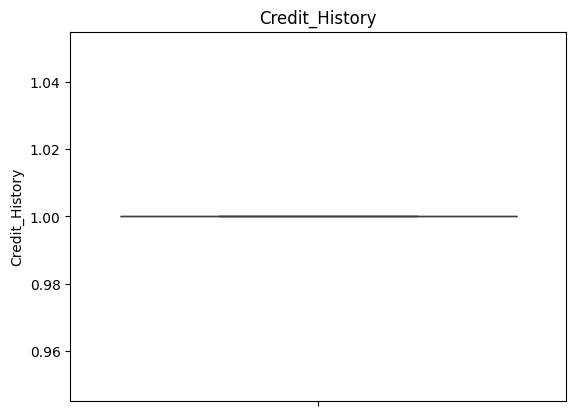

In [74]:
for i in df_without_outlier.select_dtypes("number").columns:
  print(i)
  sns.boxplot(df_without_outlier[i])
  plt.title(i)
  plt.show(i)



### ENCODING

In [75]:
df_encoded = df_without_outlier.copy()

# Encode the target separately.
df_encoded["Loan_Status"] = df_encoded["Loan_Status"].map({"N": 0, "Y": 1})

# One-hot encode nominal/text features, excluding the identifier.
feature_cols = [col for col in df_encoded.columns if col not in ["Loan_ID", "Loan_Status"]]
X = pd.get_dummies(df_encoded[feature_cols], columns=[
    col for col in feature_cols if df_encoded[col].dtype == "object"
], drop_first=False, dtype=int)

y = df_encoded["Loan_Status"]

print("Encoded feature shape:", X.shape)
print("Target values (0 = No, 1 = Yes):")
print(y.value_counts().sort_index())
display(X.head())

Encoded feature shape: (396, 20)
Target values (0 = No, 1 = Yes):
Loan_Status
0     74
1    322
Name: count, dtype: int64


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Gender_Female,Gender_Male,Married_No,Married_Yes,Dependents_0,Dependents_1,Dependents_2,Dependents_3+,Education_Graduate,Education_Not Graduate,Self_Employed_No,Self_Employed_Yes,Property_Area_Rural,Property_Area_Semiurban,Property_Area_Urban
0,5849,0.0,128.0,360.0,1.0,0,1,1,0,1,0,0,0,1,0,1,0,0,0,1
1,4583,1508.0,128.0,360.0,1.0,0,1,0,1,0,1,0,0,1,0,1,0,1,0,0
2,3000,0.0,66.0,360.0,1.0,0,1,0,1,1,0,0,0,1,0,0,1,0,0,1
3,2583,2358.0,120.0,360.0,1.0,0,1,0,1,1,0,0,0,0,1,1,0,0,0,1
4,6000,0.0,141.0,360.0,1.0,0,1,1,0,1,0,0,0,1,0,1,0,0,0,1


### SCALING

In [76]:
from sklearn.preprocessing import StandardScaler
std = StandardScaler()

df_scaled = pd.DataFrame(std.fit_transform(df_encoded[[ "ApplicantIncome","CoapplicantIncome","LoanAmount","Loan_Amount_Term" ]]),columns=[ "ApplicantIncome","CoapplicantIncome","LoanAmount","Loan_Amount_Term" ])
df_scaled

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term
0,0.960029,-0.953550,-0.010551,0.0
1,0.280905,0.109487,-0.010551,0.0
2,-0.568268,-0.953550,-1.388519,0.0
3,-0.791960,0.708679,-0.188354,0.0
4,1.041031,-0.953550,0.278377,0.0
...,...,...,...,...
391,-0.038809,0.041108,0.633982,0.0
392,-0.443816,0.421066,-0.455057,0.0
393,-0.621911,-0.953550,-1.277393,0.0
394,2.152519,-0.784367,2.767610,0.0


<Axes: xlabel='ApplicantIncome', ylabel='Density'>

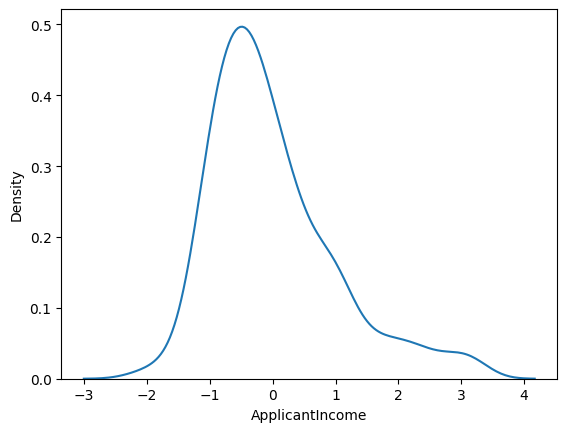

In [77]:
sns.kdeplot(df_scaled["ApplicantIncome"])